# 4. ⏪ Keep the edit, or undo it?

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/4-history-and-debugging.ipynb)

## Goal

Understand Landpy’s core **retrace** idea and distinguish it from exact undo. By the end, you can carry an edited crop home, restore a checkpoint, and use the debugger to inspect what happened.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.0 if needed. A CPU is enough. Python 3.10+ is supported; no model downloads are needed here.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
from landpy import ImageLand, MarksLand, SquareMarks, Filter, Debugger


## Steps

### 1. Retrace geometric operations

Pass `save_trace=True` to record an inverse. `retrace()` applies one inverse to the current data. Point geometry can round-trip accurately; image rotations and resizing lose information through resampling.

**Retrace keeps your edit; undo restores a snapshot.** First check the geometry with points, then compare both behaviors on pixels.

In [2]:
marks = MarksLand([[20, 30], [80, 120]], shape=(120, 180))
original = marks.get_marks().copy()
marks.move((12, -5), save_trace=True).rotate(25, save_trace=True)
marks.retrace().retrace()
np.testing.assert_allclose(marks.get_marks(), original, atol=1e-10)

### 2. Undo exact snapshots

Checkpoint **before** edits. Undo restores data and traces exactly; redo restores the edited state. A new operation after undo clears redo. `copy(copy_trace=True)` copies histories independently. Mutable array access is low-level: make a checkpoint before editing it and do not expect direct array writes to invalidate redo automatically.

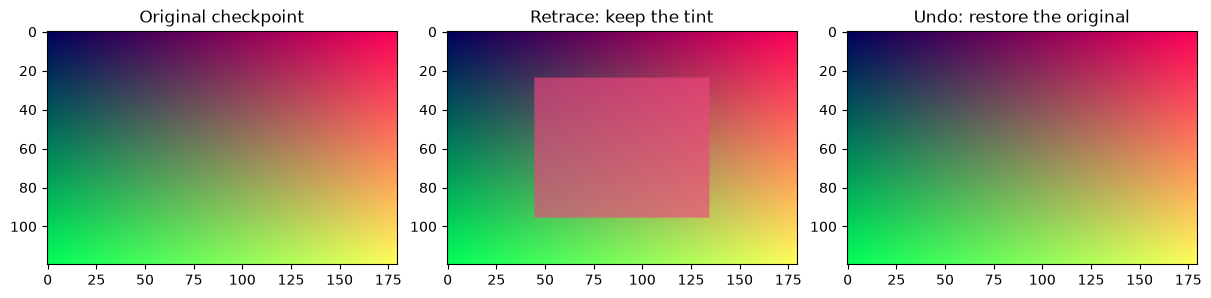

Redo restores the tinted result exactly.


In [3]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)
original = image.get_image().copy()
region = SquareMarks.relative(.2, .8, .25, .75, shape=image.shape)
visual = Debugger(visual_debug=True)
visual.save_image(image.get_image(), 'Original checkpoint')
image.make_checkpoint().zoom(region, save_trace=True)
image.implant_filter(Filter('#ed477f', .65)).retrace()
edited = image.get_image().copy()
visual.save_image(edited, 'Retrace: keep the tint')
image.undo()
np.testing.assert_array_equal(image.get_image(), original)
visual.save_image(image.get_image(), 'Undo: restore the original')
visual.log_saved_images();
image.redo()
np.testing.assert_array_equal(image.get_image(), edited)
print('Redo restores the tinted result exactly.')

### 3. Observe nested operations

A Debugger can select class names, method names or qualified method names as categories. Timing scopes and decorator categories unwind even if a method raises. Logging defaults to off on data containers.

Only movement and resizing are enabled below, so the log stays short. Each “started” / “ended” pair identifies one operation; durations vary by machine and are not a benchmark. Visual snapshots are explicit: the debugger does not automatically record every intermediate image.

In [4]:
debugger = Debugger(textual_debug=True, categories=['MarksLand.move', 'MarksLand.reshape'])
marks.set_debugger(debugger).move((2, 3)).reshape((60, 90));

MarksLand.move started
  MarksLand.move ended (0.0001s)
MarksLand.reshape started
  MarksLand.reshape ended (0.0000s)


## Checks

In [5]:
image.undo().clear_checkpoint_history()
try:
    image.undo()
except IndexError as error:
    print('Expected after clearing checkpoints:', error)
help(ImageLand.retrace)

Expected after clearing checkpoints: No checkpoint to undo.
Help on function retrace in module landpy.land:

retrace(self)
    Apply the latest inverse; raise IndexError if empty.

    Resampling inverses are approximate. Crop inverses paste edited pixels
    into the original canvas. Use checkpoints for exact restoration.



## Take it further 🚀

You have seen the difference between retrace and undo. Next, bring edits back from crops and tilted surfaces.

[Choose the next notebook](https://github.com/bateni1380/landpy/tree/master/tutorials)

**Try it:** Change the tint after making a checkpoint, then compare retrace and undo again.

➡️ **[Continue to notebook 5](https://github.com/bateni1380/landpy/blob/master/tutorials/5-crops-and-perspective.ipynb)**

[← Previous lesson](https://github.com/bateni1380/landpy/blob/master/tutorials/3-heat-maps-and-filters.ipynb)